In [1]:
%pip install pandas numpy requests

Note: you may need to restart the kernel to use updated packages.


In [2]:
import sys
from pathlib import Path
sys.path.append(str(Path.cwd().parent))

%load_ext autoreload
%autoreload 2

In [3]:
%reload_ext autoreload

In [4]:
import sys
from pathlib import Path

here = Path.cwd()
root = here if (here / "run_ingestion.py").exists() else here.parent

print("Notebook is in:", here)
print("Project folder:", root)
print("Found run_ingestion.py:", (root / "run_ingestion.py").exists())

sys.path.insert(0, str(root))

Notebook is in: C:\Users\User\Downloads\peak-season-forecaster\peak-season-forecaster\notebooks
Project folder: C:\Users\User\Downloads\peak-season-forecaster\peak-season-forecaster
Found run_ingestion.py: True


In [5]:
import sys
from pathlib import Path

here = Path.cwd()
root = here if (here / "run_ingestion.py").exists() else here.parent

print("Notebook is in:", here)
print("Project folder:", root)
print("Found run_ingestion.py:", (root / "run_ingestion.py").exists())

sys.path.insert(0, str(root))

Notebook is in: C:\Users\User\Downloads\peak-season-forecaster\peak-season-forecaster\notebooks
Project folder: C:\Users\User\Downloads\peak-season-forecaster\peak-season-forecaster
Found run_ingestion.py: True


In [6]:
from pathlib import Path

matches = list(Path.home().rglob("run_ingestion.py"))
for m in matches:
    print(m)
print("Found:", len(matches))

C:\Users\User\Downloads\peak-season-forecaster\peak-season-forecaster\run_ingestion.py
Found: 1


In [7]:
import sys
from pathlib import Path

root = Path(r"C:\Users\User\Downloads\peak-season-forecaster\peak-season-forecaster")

print("Found run_ingestion.py:", (root / "run_ingestion.py").exists())
print("Found src folder:", (root / "src").exists())

sys.path.insert(0, str(root))

Found run_ingestion.py: True
Found src folder: True


In [8]:
from run_ingestion import main
main()

2026-11-13 15:22:14,105 INFO Requesting weather 2023-01-01 to 2026-11-08
2026-11-13 15:22:15,364 INFO Saved 1408 rows to table 'weather'
2026-11-13 15:22:15,421 INFO Saved 1408 rows to table 'calendar'
2026-11-13 15:22:15,469 INFO Saved 1408 rows to table 'ops_synthetic'


In [9]:
import sqlite3
import pandas as pd
from src import config

conn = sqlite3.connect(config.DB_PATH)
pd.read_sql("select * from ops_synthetic limit 5", conn)

,date,parcels,labour_hours,uph,dpmo
0,2023-01-01 00:00:00,11168,120.6,92.6,636.0
1,2023-01-02 00:00:00,8724,90.0,96.9,881.0
2,2023-01-03 00:00:00,22836,249.8,91.4,1019.0
3,2023-01-04 00:00:00,20954,202.6,103.4,1011.0
4,2023-01-05 00:00:00,17703,199.6,88.7,692.0


In [10]:
%pip install matplotlib

Note: you may need to restart the kernel to use updated packages.


In [11]:
import sys
from pathlib import Path

root = Path(r"C:\Users\User\Downloads\peak-season-forecaster\peak-season-forecaster")
sys.path.insert(0, str(root))

import sqlite3
import pandas as pd
import matplotlib.pyplot as plt
from src import config

images = root / "images"
images.mkdir(exist_ok=True)

conn = sqlite3.connect(config.DB_PATH)
ops = pd.read_sql("select * from ops_synthetic", conn, parse_dates=["date"])
weather = pd.read_sql("select * from weather", conn, parse_dates=["date"])
calendar = pd.read_sql("select * from calendar", conn, parse_dates=["date"])

df = (ops.merge(weather, on="date")
         .merge(calendar[["date", "is_bank_holiday", "is_peak_event",
                          "is_peak_season", "day_of_week"]], on="date"))
df.head()

,date,parcels,labour_hours,uph,dpmo,temp_c,rain_mm,wind_kmh,is_bank_holiday,is_peak_event,is_peak_season,day_of_week
0,2023-01-01,11168,120.6,92.6,636.0,10.2,4.0,31.4,0,0,0,6
1,2023-01-02,8724,90.0,96.9,881.0,5.5,0.2,15.5,1,0,0,0
2,2023-01-03,22836,249.8,91.4,1019.0,8.3,3.2,37.4,0,0,0,1
3,2023-01-04,20954,202.6,103.4,1011.0,11.8,0.9,35.9,0,0,0,2
4,2023-01-05,17703,199.6,88.7,692.0,10.5,0.1,31.5,0,0,0,3


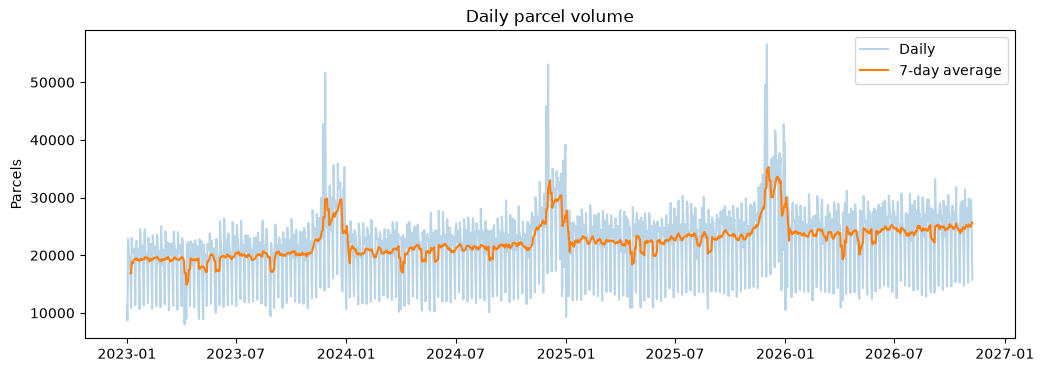

In [12]:
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(df["date"], df["parcels"], alpha=0.3, label="Daily")
ax.plot(df["date"], df["parcels"].rolling(7).mean(), label="7-day average")
ax.set_title("Daily parcel volume")
ax.set_ylabel("Parcels")
ax.legend()
plt.savefig(images / "01_volume_over_time.png", dpi=150, bbox_inches="tight")
plt.show()

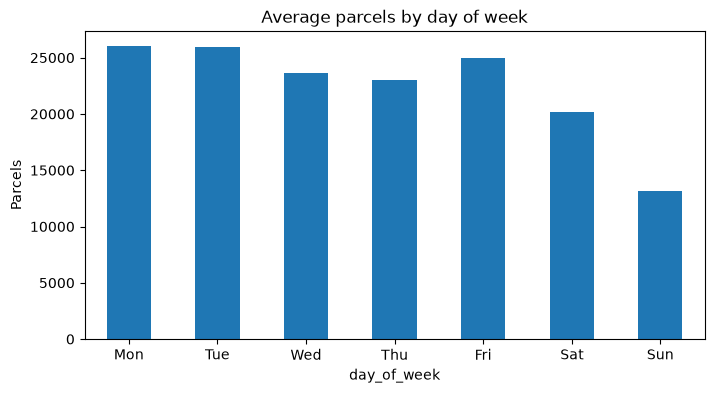

In [13]:
day_names = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
by_day = df.groupby("day_of_week")["parcels"].mean()

ax = by_day.plot(kind="bar", figsize=(8, 4))
ax.set_xticklabels(day_names, rotation=0)
ax.set_title("Average parcels by day of week")
ax.set_ylabel("Parcels")
plt.savefig(images / "02_day_of_week.png", dpi=150, bbox_inches="tight")
plt.show()

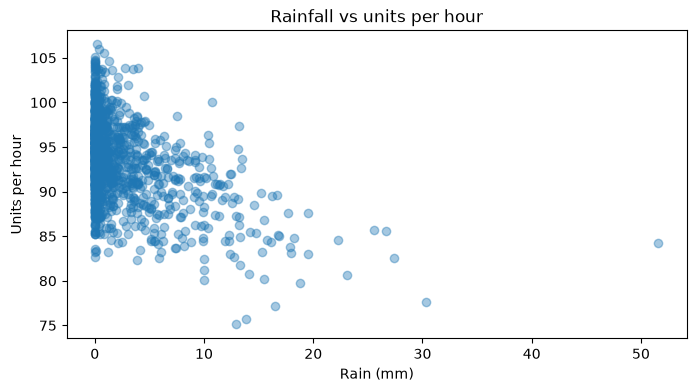

Correlation: -0.45


In [14]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.scatter(df["rain_mm"], df["uph"], alpha=0.4)
ax.set_title("Rainfall vs units per hour")
ax.set_xlabel("Rain (mm)")
ax.set_ylabel("Units per hour")
plt.savefig(images / "03_rain_vs_uph.png", dpi=150, bbox_inches="tight")
plt.show()

print("Correlation:", round(df["rain_mm"].corr(df["uph"]), 2))

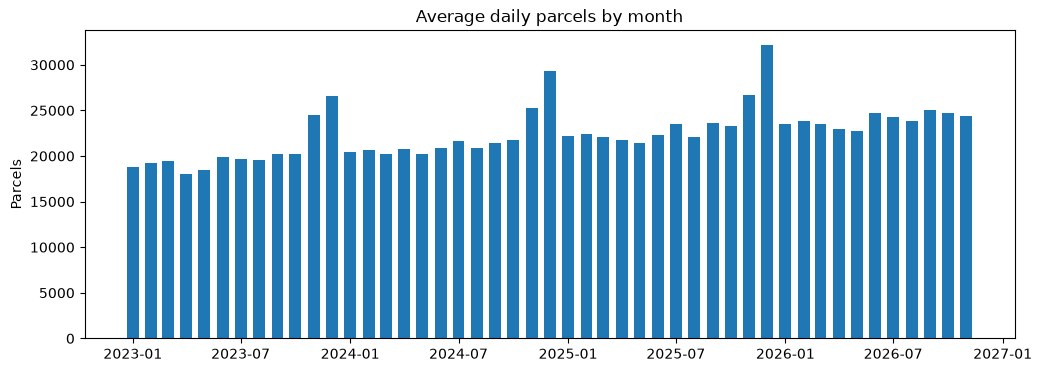

In [15]:
monthly = df.set_index("date")["parcels"].resample("MS").mean()

fig, ax = plt.subplots(figsize=(12, 4))
ax.bar(monthly.index, monthly.values, width=20)
ax.set_title("Average daily parcels by month")
ax.set_ylabel("Parcels")
plt.savefig(images / "04_monthly_average.png", dpi=150, bbox_inches="tight")
plt.show()

In [16]:
import sys
from pathlib import Path

root = Path(r"C:\Users\User\Downloads\peak-season-forecaster\peak-season-forecaster")
sys.path.insert(0, str(root))

import sqlite3
import pandas as pd
import matplotlib.pyplot as plt
from src import config

images = root / "images"
images.mkdir(exist_ok=True)

conn = sqlite3.connect(config.DB_PATH)
df = (pd.read_sql("select * from ops_synthetic", conn, parse_dates=["date"])
        .sort_values("date")
        .set_index("date"))
df.tail()

,parcels,labour_hours,uph,dpmo
date,,,,
2026-11-04,26145,280.8,93.1,915.0
2026-11-05,25717,275.6,93.3,1152.0
2026-11-06,29605,322.8,91.7,1061.0
2026-11-07,23650,248.9,95.0,1329.0
2026-11-08,15728,169.8,92.6,714.0


In [17]:
# Baseline 1: average of the previous 7 days
df["ma7"] = df["parcels"].shift(1).rolling(7).mean()

# Baseline 2: same weekday last week
df["seasonal_naive"] = df["parcels"].shift(7)

# Test on the 2025 peak season, the hardest part of the year
test = df.loc["2025-11-01":"2025-12-31"].copy()

def score(actual, predicted):
    mae = (actual - predicted).abs().mean()
    mape = ((actual - predicted).abs() / actual).mean() * 100
    return round(mae), round(mape, 1)

results = pd.DataFrame(
    {name: score(test["parcels"], test[name]) for name in ["ma7", "seasonal_naive"]},
    index=["MAE (parcels)", "MAPE (%)"],
).T
results

,MAE (parcels),MAPE (%)
ma7,6278.0,25.8
seasonal_naive,3824.0,13.9


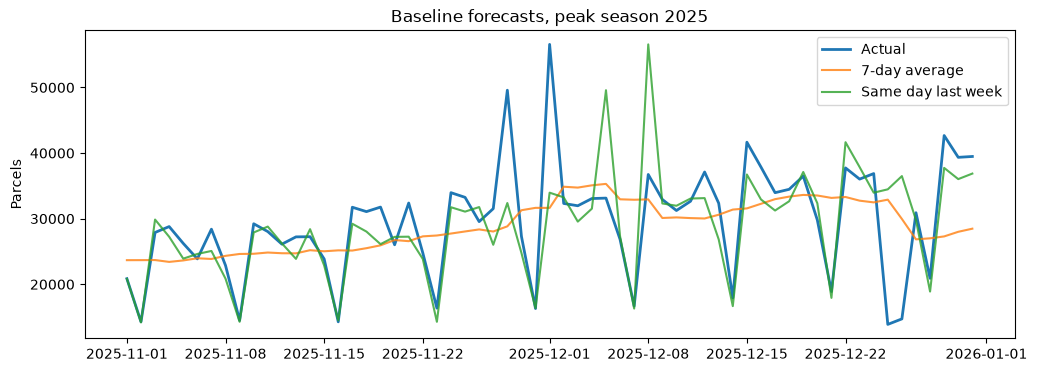

In [18]:
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(test.index, test["parcels"], label="Actual", linewidth=2)
ax.plot(test.index, test["ma7"], label="7-day average", alpha=0.8)
ax.plot(test.index, test["seasonal_naive"], label="Same day last week", alpha=0.8)
ax.set_title("Baseline forecasts, peak season 2025")
ax.set_ylabel("Parcels")
ax.legend()
plt.savefig(images / "05_baselines.png", dpi=150, bbox_inches="tight")
plt.show()